# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> YMLS Uzbekistan, ML Fundamentals, fall 2026 <a class="tocSkip">

# Week 5 seminar. Classification metrics and optimisation methods

Part A measures a classifier on fake listings, where only 5% of the objects are positive: the confusion matrix, precision, recall and F1 by hand, the threshold, ROC and precision-recall curves, class weights and cross-validation with a metric of our choice. Part B trains logistic regression by hand: gradient descent and the condition number, momentum, Adam and mini-batch SGD.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/girafe-ai/ml-course/blob/26f_ymls_uz/week0_05_metrics_and_optimisation/week0_05_01_metrics_and_optimisation__completed.ipynb)

This week's [lecture slides](https://github.com/girafe-ai/ml-course/blob/26f_ymls_uz/week0_05_metrics_and_optimisation/ml-basic_lect05_metrics_optimisation.pdf) are in the same folder. The links to the interactive pages are in the course chat.

_YMLS Uzbekistan, ML Fundamentals, fall 2026_

_Completed version with solutions and outputs. The student version is `week0_05_01_metrics_and_optimisation.ipynb`._

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


SEED = 42  # one seed for every split and random generator


def sigmoid(z):
    """The logistic function 1 / (1 + exp(-z))."""
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


# Plot style: gray axes, colour only for data
INK, INK2, INK3, LINE = "#1D1D1F", "#6E6E73", "#86868B", "#D2D2D7"
ACCENT, ORANGE, GREEN, PURPLE = "#0071E3", "#FF9F0A", "#34C759", "#AF52DE"
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 13,
        "mathtext.fontset": "cm",
        "axes.edgecolor": LINE,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "axes.prop_cycle": plt.cycler(color=[ACCENT, ORANGE, GREEN, PURPLE, INK3]),
        "xtick.color": INK3,
        "ytick.color": INK3,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "xtick.minor.size": 0,
        "ytick.minor.size": 0,
        "legend.frameon": False,
        "legend.fontsize": 11,
        "lines.linewidth": 2.2,
        "lines.markersize": 6,
        "figure.facecolor": "white",
    }
)

## Part A. Classification metrics

Week 4 ended with one number, the accuracy on new flats. A loss is what the model minimises on the training data, so it has to be smooth. A metric is what we report on validation and test data, so it has to say what we care about. This part builds the common metrics by hand and checks each one against `sklearn.metrics`.

## 1. Fake listings and accuracy

A classified site has a problem with fake listings: baits for flats that do not exist. About 5% of all listings are fakes. A listing has three features. `markup` is the asking price against the market estimate, in percent. `photos` is the number of photos. `age` is the age of the seller's account in months. The label `fake` is 1 for a fake and 0 for a real listing. The data is synthetic. We train on 2 000 listings with exactly 100 fakes and test on 4 000 new ones with exactly 200 fakes.

train: 2000 listings, 100 fakes
test:  4000 listings, 200 fakes
mean of markup, photos, age for real listings: [ 3.7 10.  31.1]
mean of markup, photos, age for fakes:         [-10.7   6.    9.6]


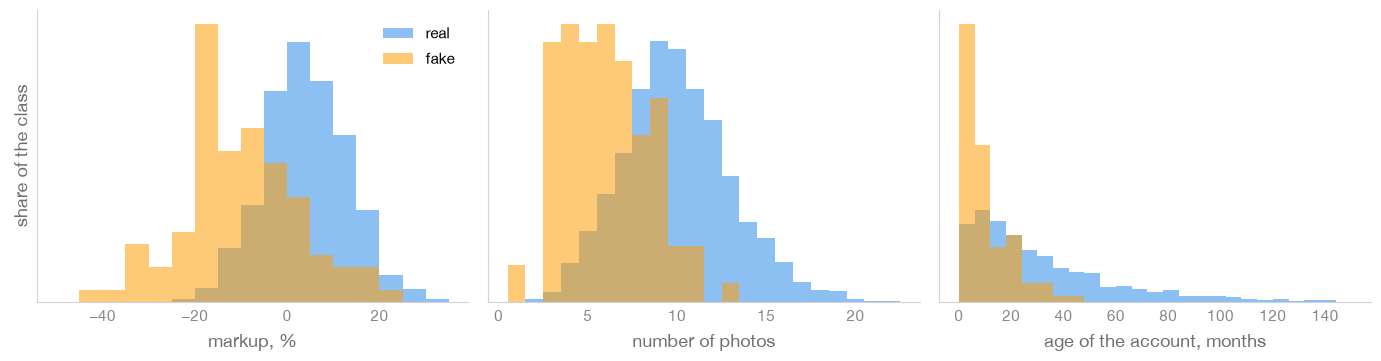

In [2]:
FEATURES = ["markup", "photos", "age"]


def fake_sample(seed, n, share=0.05):
    """n listings, the given share of them fake: a matrix with the columns of FEATURES, and y."""
    rng = np.random.default_rng(seed)
    y = np.zeros(n, dtype=int)
    y[: int(round(share * n))] = 1
    rng.shuffle(y)
    markup = np.round(np.where(y == 1, rng.normal(-12, 11, n), rng.normal(4, 9, n)))
    photos = np.where(y == 1, rng.poisson(5, n), rng.poisson(9, n)) + 1
    age = np.round(np.where(y == 1, rng.exponential(8, n), rng.exponential(30, n)) + 1)
    return np.column_stack([markup, photos, age]).astype(float), y


X_train, y_train = fake_sample(1, 2000)  # the listings we train on
X_test, y_test = fake_sample(5001, 4000)  # new listings, the test set

print(f"train: {len(y_train)} listings, {y_train.sum()} fakes")
print(f"test:  {len(y_test)} listings, {y_test.sum()} fakes")
print("mean of markup, photos, age for real listings:", X_train[y_train == 0].mean(axis=0).round(1))
print("mean of markup, photos, age for fakes:        ", X_train[y_train == 1].mean(axis=0).round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
labels = ["markup, %", "number of photos", "age of the account, months"]
bins = [np.arange(-50, 36, 5), np.arange(0.5, 23.5, 1), np.arange(0, 151, 6)]
for j, (ax, label, edges) in enumerate(zip(axes, labels, bins, strict=True)):
    ax.hist(
        X_train[y_train == 0, j], bins=edges, density=True, color=ACCENT, alpha=0.45, label="real"
    )
    ax.hist(
        X_train[y_train == 1, j], bins=edges, density=True, color=ORANGE, alpha=0.55, label="fake"
    )
    ax.set(xlabel=label, yticks=[])
axes[0].set_ylabel("share of the class")
axes[0].legend()
fig.tight_layout()
plt.show()

Fakes are cheap: their mean markup is $-10.7$% against 3.7% for real listings. They also have fewer photos (6.0 against 10.0 on average) and come from younger accounts (9.6 months against 31.1). The histograms overlap in every feature, so no single one separates the classes.

### 1.1 Accuracy

The baseline flags nothing. The model is the one from week 4: standardise the features, then fit logistic regression without a penalty. A listing is flagged when its predicted probability of being a fake is at least 0.5.

In [3]:
def make_model(class_weight=None):
    """Standardise the features, then logistic regression without a penalty."""
    # C=np.inf switches the penalty off; the small tol makes the fit exact to many digits
    logreg = LogisticRegression(C=np.inf, class_weight=class_weight, max_iter=100_000, tol=1e-10)
    return make_pipeline(StandardScaler(), logreg)


model = make_model().fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]  # the predicted probability of "fake"
flagged = p_test >= 0.5  # True for the listings the model flags
flag_nothing = np.zeros(len(y_test), dtype=bool)  # the baseline: no listing is flagged

print(
    f"intercept {model[-1].intercept_[0]:.3f}, weights of markup, photos, age:",
    model[-1].coef_[0].round(3),
)
print(f"accuracy of flagging nothing:    {np.mean(flag_nothing == y_test):.3f}")
print(f"accuracy of logistic regression: {np.mean(flagged == y_test):.3f}")

intercept -6.558, weights of markup, photos, age: [-1.632 -1.852 -2.875]
accuracy of flagging nothing:    0.950
accuracy of logistic regression: 0.971


Flagging nothing is right for 95.0% of the listings and catches no fake. Logistic regression reaches 0.971. Accuracy puts the two about two points apart, and it does not say how many fakes the model catches or how many honest sellers it accuses.

### 1.2 The confusion matrix

The positive class is 1, a fake. Every test listing falls into one of four groups:

| | flagged | not flagged |
| --- | --- | --- |
| fake | true positive, TP | false negative, FN |
| real | false positive, FP | true negative, TN |

**Exercise 1.1.** Write `confusion_counts(y, flagged)`. It returns the four counts TP, FP, FN, TN.

In [4]:
def confusion_counts(y, flagged):
    """TP, FP, FN, TN for the labels y (1 is a fake) and a boolean array of flags."""
    fake = y == 1
    tp = np.sum(flagged & fake)
    fp = np.sum(flagged & ~fake)
    fn = np.sum(~flagged & fake)
    tn = np.sum(~flagged & ~fake)
    return int(tp), int(fp), int(fn), int(tn)

In [5]:
counts = confusion_counts(y_test, flagged)
assert counts is not None, "Fill in confusion_counts above"
tp, fp, fn, tn = counts
assert (tp, fp, fn, tn) == (119, 35, 81, 3765), (
    "Expect TP 119, FP 35, FN 81, TN 3765: a true positive is flagged and is a fake, "
    "a false negative is a fake that is not flagged"
)
print("         flagged   not flagged")
print(f"fake {tp:11d} {fn:13d}")
print(f"real {fp:11d} {tn:13d}")
print("\nconfusion_matrix from scikit-learn:")
print(confusion_matrix(y_test, flagged.astype(int)))

         flagged   not flagged
fake         119            81
real          35          3765

confusion_matrix from scikit-learn:
[[3765   35]
 [  81  119]]


Of the 200 fakes the model catches 119 and misses 81. Of the 3 800 real listings it flags 35. `confusion_matrix` from scikit-learn holds the same four numbers in another layout: the rows are the true classes 0 and 1, the columns are the predicted ones, so TN is in the top left corner.

### 1.3 Precision, recall and F1

$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}.$$

Precision is the share of fakes among the flagged listings, $P(\text{fake} \mid \text{flagged})$. Recall is the share of the fakes that got flagged, $P(\text{flagged} \mid \text{fake})$. $F_1$ is their harmonic mean, which stays close to the smaller of the two.

**Exercise 1.2.** Write `precision_recall_f1(tp, fp, fn)`.

In [6]:
def precision_recall_f1(tp, fp, fn):
    """Precision, recall and F1 from the counts. A ratio 0 / 0 counts as 0."""
    if tp == 0:
        return 0.0, 0.0, 0.0  # nothing was caught: every ratio is 0 or 0 / 0
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)
    return precision, recall, f1

In [7]:
assert confusion_counts(y_test, flagged) is not None, "Finish Exercise 1.1 first"
tp, fp, fn, tn = confusion_counts(y_test, flagged)
scores = precision_recall_f1(tp, fp, fn)
assert scores is not None, "Fill in precision_recall_f1 above"
precision_05, recall_05, f1_05 = scores
predicted = flagged.astype(int)  # scikit-learn wants labels 0 and 1
assert np.isclose(precision_05, precision_score(y_test, predicted)), "Precision is TP / (TP + FP)"
assert np.isclose(recall_05, recall_score(y_test, predicted)), "Recall is TP / (TP + FN)"
assert np.isclose(f1_05, f1_score(y_test, predicted)), "F1 is 2 P R / (P + R)"
print("              by hand   sklearn.metrics")
print(f"precision {precision_05:11.3f} {precision_score(y_test, predicted):17.3f}")
print(f"recall    {recall_05:11.3f} {recall_score(y_test, predicted):17.3f}")
print(f"F1        {f1_05:11.3f} {f1_score(y_test, predicted):17.3f}")
print("flagging nothing:", precision_recall_f1(*confusion_counts(y_test, flag_nothing)[:3]))

              by hand   sklearn.metrics
precision       0.773             0.773
recall          0.595             0.595
F1              0.672             0.672
flagging nothing: (0.0, 0.0, 0.0)


Precision is 119 / 154 = 0.773 and recall is 119 / 200 = 0.595. Three of four flags are right, and two of five fakes get through. $F_1$ is 0.672. The baseline that flags nothing has a recall of 0, and its precision is 0 / 0, which we count as 0. The two models are 0.021 apart in accuracy and 0.595 apart in recall.

## 2. The threshold

The model returns a probability, and the threshold 0.5 was our choice. A lower threshold flags more listings, so recall goes up and precision goes down.

**Exercise 2.1.** For every threshold from 0.01 to 0.99, compute precision, recall and $F_1$ on the test listings and append them to the three lists.

In [8]:
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)  # 0.01, 0.02, ..., 0.99
precisions, recalls, f1s = [], [], []
for t in thresholds:
    tp, fp, fn, tn = confusion_counts(y_test, p_test >= t)
    precision, recall, f1 = precision_recall_f1(tp, fp, fn)
    precisions.append(precision)
    recalls.append(recall)
    f1s.append(f1)
precisions, recalls, f1s = np.array(precisions), np.array(recalls), np.array(f1s)

threshold    TP    FP    FN     TN   accuracy   precision   recall      F1
     0.05   186   429    14   3371      0.889       0.302    0.930   0.456
     0.10   176   260    24   3540      0.929       0.404    0.880   0.553
     0.20   157   132    43   3668      0.956       0.543    0.785   0.642
     0.30   148    88    52   3712      0.965       0.627    0.740   0.679
     0.39   136    56    64   3744      0.970       0.708    0.680   0.694
     0.50   119    35    81   3765      0.971       0.773    0.595   0.672
     0.70    88    11   112   3789      0.969       0.889    0.440   0.589
     0.90    45     3   155   3797      0.961       0.938    0.225   0.363

best F1: 0.694 at the threshold 0.39


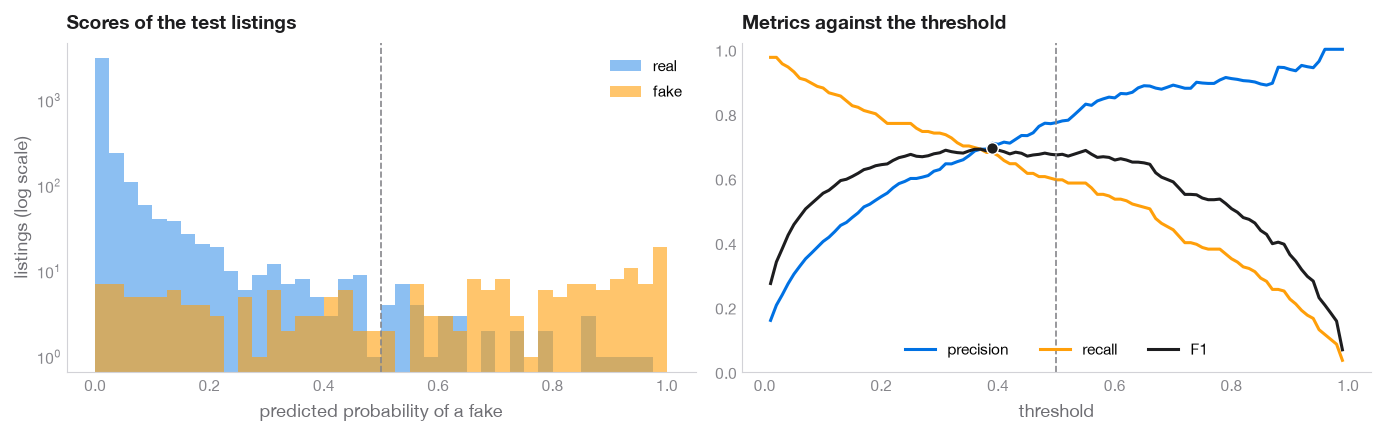

In [9]:
assert len(f1s) == len(
    thresholds
), "Fill in the loop above: one value per threshold in each of the three lists"
i_best = int(np.argmax(f1s))
t_best = thresholds[i_best]
assert np.isclose(f1s[i_best], 0.694, atol=5e-4) and np.isclose(
    t_best, 0.39
), "Expect the best F1 0.694 at the threshold 0.39: a listing is flagged when p_test >= t"

print("threshold    TP    FP    FN     TN   accuracy   precision   recall      F1")
for t in [0.05, 0.1, 0.2, 0.3, 0.39, 0.5, 0.7, 0.9]:
    tp, fp, fn, tn = confusion_counts(y_test, p_test >= t)
    precision, recall, f1 = precision_recall_f1(tp, fp, fn)
    accuracy = (tp + tn) / len(y_test)
    print(
        f"{t:9.2f} {tp:5d} {fp:5d} {fn:5d} {tn:6d} {accuracy:10.3f} {precision:11.3f} "
        f"{recall:8.3f} {f1:7.3f}"
    )
print(f"\nbest F1: {f1s[i_best]:.3f} at the threshold {t_best:.2f}")

fig, (ax_hist, ax_thr) = plt.subplots(1, 2, figsize=(14, 4.5))
edges = np.linspace(0, 1, 41)
ax_hist.hist(p_test[y_test == 0], bins=edges, color=ACCENT, alpha=0.45, label="real")
ax_hist.hist(p_test[y_test == 1], bins=edges, color=ORANGE, alpha=0.6, label="fake")
ax_hist.axvline(0.5, color=INK3, ls="--", lw=1.2)
ax_hist.set(
    yscale="log",
    xlabel="predicted probability of a fake",
    ylabel="listings (log scale)",
    title="Scores of the test listings",
)
ax_hist.legend()
ax_thr.plot(thresholds, precisions, color=ACCENT, label="precision")
ax_thr.plot(thresholds, recalls, color=ORANGE, label="recall")
ax_thr.plot(thresholds, f1s, color=INK, label="F1")
ax_thr.scatter([t_best], [f1s[i_best]], s=70, color=INK, edgecolor="white", zorder=4)
ax_thr.axvline(0.5, color=INK3, ls="--", lw=1.2)
ax_thr.set(xlabel="threshold", ylim=(0, 1.02), title="Metrics against the threshold")
ax_thr.legend(loc="lower center", ncol=3)
fig.tight_layout()
plt.show()

At the threshold 0.05 the model catches 186 of the 200 fakes and flags 429 real listings on the way, so its precision is 0.302. At 0.9 precision is 0.938 and recall is 0.225. $F_1$ is highest at the threshold 0.39, where it is 0.694. The left plot shows where the trade comes from: the scores of the two classes overlap, and any threshold cuts through both. The page `01_threshold_and_confusion.html` has this picture with a slider.

We found 0.39 by looking at the test listings. Section 4.3 comes back to that.

### 2.1 A threshold from the costs

$F_1$ treats the two kinds of mistake alike. Often they have different prices. Suppose a missed fake costs the site 10 (a user gets cheated) and a false alarm costs 1 (a moderator checks a real listing). For a listing with the probability $p$ of being a fake, leaving it costs $p \cdot c_{FN}$ on average and flagging it costs $(1 - p) \cdot c_{FP}$. Flagging is the cheaper choice when

$$p \cdot c_{FN} \ge (1 - p) \cdot c_{FP} \quad\Longleftrightarrow\quad p \ge \frac{c_{FP}}{c_{FP} + c_{FN}} = \frac{1}{11} \approx 0.09.$$

**Exercise 2.2.** Write `total_cost(y, flagged)`, the cost of all mistakes on a set of listings, and set `t_cost` to the threshold from the formula.

In [10]:
COST_MISSED_FAKE, COST_FALSE_ALARM = 10, 1


def total_cost(y, flagged):
    """What the mistakes cost: 10 for every missed fake, 1 for every false alarm."""
    tp, fp, fn, tn = confusion_counts(y, flagged)
    return fn * COST_MISSED_FAKE + fp * COST_FALSE_ALARM


t_cost = COST_FALSE_ALARM / (COST_FALSE_ALARM + COST_MISSED_FAKE)

flag nothing:              2000
threshold 0.5:             845
threshold 1/11 = 0.091:    509
lowest on the grid:        496 at the threshold 0.13


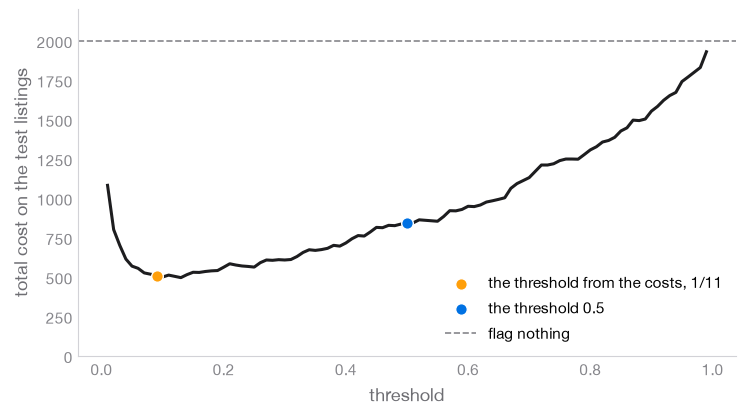

In [11]:
assert confusion_counts(y_test, flagged) is not None, "Finish Exercise 1.1 first"
assert total_cost(y_test, flagged) is not None, "Fill in total_cost above"
assert t_cost is not None, "Fill in t_cost above"
assert total_cost(y_test, flag_nothing) == 2000, "Flagging nothing misses 200 fakes: 200 * 10"
assert total_cost(y_test, flagged) == 845, "Expect 845 at the threshold 0.5: 81 * 10 + 35 * 1"
assert np.isclose(t_cost, 1 / 11), "Expect t_cost = 1 / (1 + 10)"

costs = np.array([total_cost(y_test, p_test >= t) for t in thresholds])
cost_at_t_cost = total_cost(y_test, p_test >= t_cost)
print(f"flag nothing:              {total_cost(y_test, flag_nothing)}")
print(f"threshold 0.5:             {total_cost(y_test, flagged)}")
print(f"threshold 1/11 = {t_cost:.3f}:    {cost_at_t_cost}")
print(f"lowest on the grid:        {costs.min()} at the threshold {thresholds[costs.argmin()]:.2f}")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(thresholds, costs, color=INK)
ax.scatter(
    [t_cost],
    [cost_at_t_cost],
    s=70,
    color=ORANGE,
    edgecolor="white",
    zorder=4,
    label="the threshold from the costs, 1/11",
)
ax.scatter(
    [0.5],
    [total_cost(y_test, flagged)],
    s=70,
    color=ACCENT,
    edgecolor="white",
    zorder=4,
    label="the threshold 0.5",
)
ax.axhline(total_cost(y_test, flag_nothing), color=INK3, ls="--", lw=1.2, label="flag nothing")
ax.set(xlabel="threshold", ylabel="total cost on the test listings", ylim=(0, 2200))
ax.legend(loc="lower right")
plt.show()

Flagging nothing costs 2 000, the threshold 0.5 costs 845 and the threshold 1/11 costs 509. The curve is flat near its bottom: the lowest cost on our grid is 496, at the threshold 0.13. The formula assumes that the probabilities are exact, and the 4 000 listings are one sample, so the two thresholds differ a little.

## 3. ROC and precision-recall curves

A threshold belongs to one use of the model. To judge the scores themselves we look at all thresholds at once.

### 3.1 ROC-AUC as a share of pairs

Recall has two more names: sensitivity and the true positive rate, TPR. Its partner is the false positive rate, the share of real listings that get flagged:

$$\text{TPR} = \frac{TP}{TP + FN}, \qquad \text{FPR} = \frac{FP}{FP + TN} = 1 - \text{specificity}.$$

The ROC curve plots TPR against FPR for every threshold, and ROC-AUC is the area under it. The area has a direct meaning: it is the share of pairs (fake, real) in which the fake has the higher score. Below are twelve of the test listings sorted by score, 4 fakes and 8 real ones.

**Exercise 3.1.** Count the pairs in which the fake has the higher score.

In [12]:
hand_score = np.array([0.96, 0.94, 0.89, 0.78, 0.53, 0.25, 0.20, 0.14, 0.12, 0.09, 0.06, 0.03])
hand_fake = np.array([1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0])
n_pairs = int(np.sum(hand_fake == 1) * np.sum(hand_fake == 0))  # every fake with every real one
n_right = 0
for fake_score in hand_score[hand_fake == 1]:
    for real_score in hand_score[hand_fake == 0]:
        if fake_score > real_score:
            n_right += 1

In [13]:
assert n_right is not None, "Fill in n_right above"
assert n_pairs == 32 and n_right == 27, "Expect 27 of the 32 pairs"
print(f"{n_right} of {n_pairs} pairs are in the right order: {n_right / n_pairs:.4f}")
print(f"roc_auc_score on the twelve listings:   {roc_auc_score(hand_fake, hand_score):.4f}")

27 of 32 pairs are in the right order: 0.8438
roc_auc_score on the twelve listings:   0.8438


27 of the 32 pairs are in the right order, so the AUC is 27 / 32 = 0.84. All five wrong pairs contain the fake with the score 0.12: five real listings stand above it.

### 3.2 The curve: a walk down the sorted list

Sort the listings by score, the highest first, and flag the first $k$ of them. Every step down the list flags one more listing. A fake raises TP by one, a real listing raises FP by one.

**Exercise 3.2.** Finish `counts_down_the_list(y, score)`: the arrays of TP and FP for $k = 1, 2, \dots, n$.

In [14]:
def counts_down_the_list(y, score):
    """TP and FP when the first k listings of the list sorted by score are flagged, for every k."""
    order = np.argsort(-score, kind="stable")  # the highest score first
    tp = np.cumsum(y[order])  # fakes among the first k listings
    fp = np.cumsum(1 - y[order])  # real listings among the first k
    # listings with equal scores are flagged together, so keep the last one of each group
    score_sorted = score[order]
    last = np.append(score_sorted[1:] != score_sorted[:-1], True)
    return tp[last], fp[last]

In [15]:
tp_hand, fp_hand = counts_down_the_list(hand_fake, hand_score)
assert np.array_equal(
    tp_hand, [1, 2, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4]
), "TP after each of the twelve steps should be 1, 2, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4"
assert np.array_equal(
    fp_hand, [0, 0, 0, 1, 2, 3, 4, 5, 5, 6, 7, 8]
), "FP after each of the twelve steps should be 0, 0, 0, 1, 2, 3, 4, 5, 5, 6, 7, 8"
print("score   fake   TP   FP    TPR     FPR")
for score, label, tp_k, fp_k in zip(hand_score, hand_fake, tp_hand, fp_hand, strict=True):
    print(f"{score:5.2f} {label:6d} {tp_k:4d} {fp_k:4d} {tp_k / 4:6.2f} {fp_k / 8:7.3f}")

score   fake   TP   FP    TPR     FPR
 0.96      1    1    0   0.25   0.000
 0.94      1    2    0   0.50   0.000
 0.89      1    3    0   0.75   0.000
 0.78      0    3    1   0.75   0.125
 0.53      0    3    2   0.75   0.250
 0.25      0    3    3   0.75   0.375
 0.20      0    3    4   0.75   0.500
 0.14      0    3    5   0.75   0.625
 0.12      1    4    5   1.00   0.625
 0.09      0    4    6   1.00   0.750
 0.06      0    4    7   1.00   0.875
 0.03      0    4    8   1.00   1.000


The last two columns are the curve: TP divided by the number of fakes and FP divided by the number of real listings.

**Exercise 3.3.** Write `roc_points(y, score)`, which turns the counts into the points of the ROC curve, and `area_under(x, y)`, the area under a broken line by the trapezoid rule:

$$\text{area} = \sum_i (x_{i+1} - x_i) \cdot \frac{y_i + y_{i+1}}{2}.$$

In [16]:
def roc_points(y, score):
    """The ROC curve: the arrays FPR and TPR, starting from the point (0, 0)."""
    tp, fp = counts_down_the_list(y, score)
    tpr = tp / tp[-1]  # the last count is the number of all fakes
    fpr = fp / fp[-1]
    return np.append(0, fpr), np.append(0, tpr)


def area_under(x, y):
    """The area under the broken line through the points (x, y), by the trapezoid rule."""
    return np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2)

twelve listings: area 0.8438, the share of pairs was 0.8438
4000 listings:   area 0.9713, roc_auc_score 0.9713


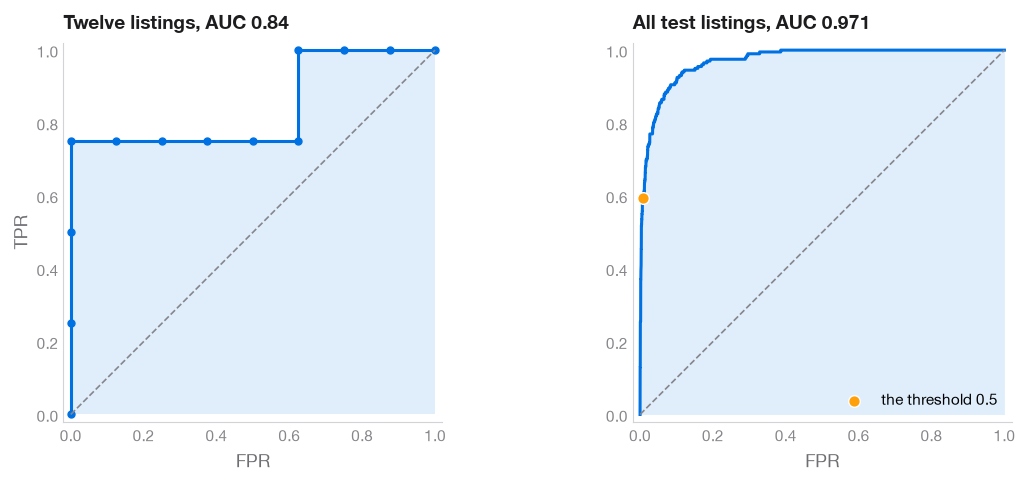

In [17]:
assert confusion_counts(y_test, flagged) is not None, "Finish Exercise 1.1 first"
roc_hand = roc_points(hand_fake, hand_score)
assert roc_hand is not None, "Fill in roc_points above"
assert (
    area_under(np.array([0.0, 1.0]), np.array([0.0, 1.0])) is not None
), "Fill in area_under above"
fpr_hand, tpr_hand = roc_hand
assert (
    len(fpr_hand) == 13 and fpr_hand[0] == 0 and tpr_hand[0] == 0
), "The curve starts at the point (0, 0): put a 0 in front of both arrays"
auc_hand = area_under(fpr_hand, tpr_hand)
assert np.isclose(auc_hand, 27 / 32), "Expect the area 27 / 32 on the twelve listings"

fpr, tpr = roc_points(y_test, p_test)
auc = area_under(fpr, tpr)
assert np.isclose(auc, roc_auc_score(y_test, p_test)), "The area differs from roc_auc_score"
print(f"twelve listings: area {auc_hand:.4f}, the share of pairs was {27 / 32:.4f}")
print(f"4000 listings:   area {auc:.4f}, roc_auc_score {roc_auc_score(y_test, p_test):.4f}")

tp, fp, fn, tn = confusion_counts(y_test, flagged)
fig, (ax_hand, ax_all) = plt.subplots(1, 2, figsize=(12, 5))
ax_hand.plot(fpr_hand, tpr_hand, "o-", color=ACCENT, ms=5)
ax_hand.fill_between(fpr_hand, tpr_hand, color=ACCENT, alpha=0.12, linewidth=0)
ax_hand.set(xlabel="FPR", ylabel="TPR", title=f"Twelve listings, AUC {auc_hand:.2f}")
ax_all.plot(fpr, tpr, color=ACCENT)
ax_all.fill_between(fpr, tpr, color=ACCENT, alpha=0.12, linewidth=0)
ax_all.scatter(
    [fp / (fp + tn)],
    [tp / (tp + fn)],
    s=70,
    color=ORANGE,
    edgecolor="white",
    zorder=4,
    label="the threshold 0.5",
)
ax_all.set(xlabel="FPR", title=f"All test listings, AUC {auc:.3f}")
ax_all.legend(loc="lower right")
for ax in (ax_hand, ax_all):
    ax.plot([0, 1], [0, 1], color=INK3, ls="--", lw=1.2)  # random scores
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal")
fig.tight_layout()
plt.show()

On the twelve listings every fake moves the curve up by 1/4 and every real listing moves it right by 1/8, and the area is 27 / 32 again. On all 4 000 test listings the area is 0.971, the number that `roc_auc_score` returns. The dot is the threshold 0.5, with a TPR of 0.595 at an FPR of 0.0092. The page `02_roc_and_pr.html` steps through the twelve listings.

The curve was built from the order of the listings alone. The next cell changes the scores without changing their order, and then replaces them with random numbers.

In [18]:
log_odds = np.log(p_test / (1 - p_test))
random_score = np.random.default_rng(SEED).uniform(size=len(y_test))
print(f"the probabilities: {roc_auc_score(y_test, p_test):.4f}")
print(f"their log-odds:    {roc_auc_score(y_test, log_odds):.4f}")
print(f"their cubes:       {roc_auc_score(y_test, p_test**3):.4f}")
print(f"random scores:     {roc_auc_score(y_test, random_score):.4f}")

the probabilities: 0.9713
their log-odds:    0.9713
their cubes:       0.9713
random scores:     0.5080


ROC-AUC does not change under any increasing transformation of the scores, and it does not depend on a threshold. Random scores get about 0.5.

### 3.3 The precision-recall curve

The same walk down the list gives a precision and a recall at every step. The precision-recall curve plots one against the other. Its summary is the average precision: the mean of the precision over the steps, each step weighted by the recall it adds,

$$\text{AP} = \sum_k (R_k - R_{k-1}) \, P_k, \qquad R_0 = 0.$$

**Exercise 3.4.** Write `pr_points(y, score)`: the arrays of precision and recall after every step.

In [19]:
def pr_points(y, score):
    """Precision and recall when the first k listings of the sorted list are flagged."""
    tp, fp = counts_down_the_list(y, score)
    precision = tp / (tp + fp)
    recall = tp / tp[-1]
    return precision, recall

average precision by hand 0.7519, average_precision_score 0.7519
the best precision with a recall of at least 0.9: 0.367


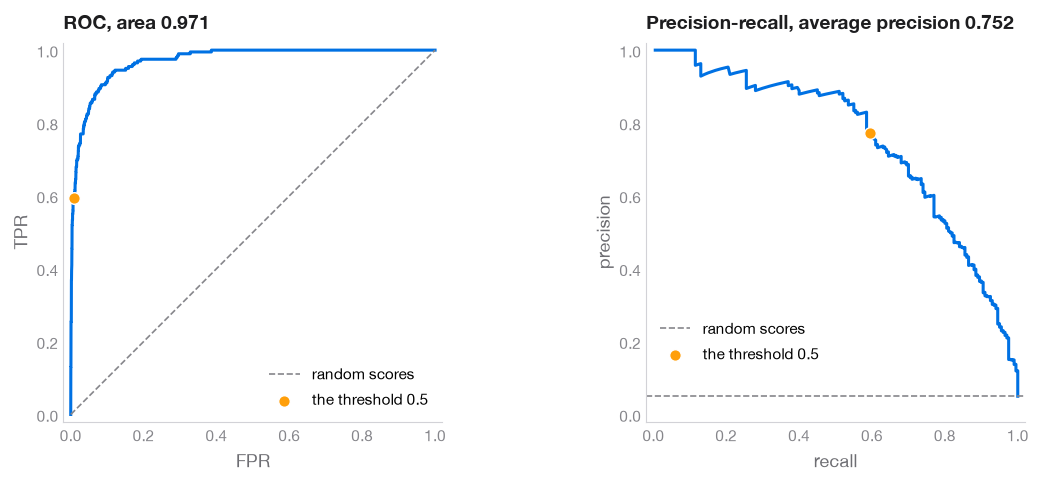

In [20]:
assert roc_points(hand_fake, hand_score) is not None, "Finish Exercise 3.3 first"
assert (
    area_under(np.array([0.0, 1.0]), np.array([0.0, 1.0])) is not None
), "Finish Exercise 3.3 first"
pr = pr_points(y_test, p_test)
assert pr is not None, "Fill in pr_points above"
pr_precision, pr_recall = pr
ap = np.sum(np.diff(pr_recall, prepend=0) * pr_precision)  # the formula above
assert np.isclose(
    ap, average_precision_score(y_test, p_test)
), "The average precision differs from average_precision_score: check precision and recall"
precision_at_90 = pr_precision[pr_recall >= 0.9].max()
print(
    f"average precision by hand {ap:.4f}, average_precision_score "
    f"{average_precision_score(y_test, p_test):.4f}"
)
print(f"the best precision with a recall of at least 0.9: {precision_at_90:.3f}")

tp, fp, fn, tn = confusion_counts(y_test, flagged)
fpr, tpr = roc_points(y_test, p_test)
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
ax_roc.plot(fpr, tpr, color=ACCENT)
ax_roc.plot([0, 1], [0, 1], color=INK3, ls="--", lw=1.2, label="random scores")
ax_roc.scatter(
    [fp / (fp + tn)],
    [tp / (tp + fn)],
    s=70,
    color=ORANGE,
    edgecolor="white",
    zorder=4,
    label="the threshold 0.5",
)
ax_roc.set(xlabel="FPR", ylabel="TPR", title=f"ROC, area {area_under(fpr, tpr):.3f}")
ax_roc.legend(loc="lower right")
ax_pr.plot(pr_recall, pr_precision, color=ACCENT)
ax_pr.axhline(y_test.mean(), color=INK3, ls="--", lw=1.2, label="random scores")
ax_pr.scatter(
    [tp / (tp + fn)],
    [tp / (tp + fp)],
    s=70,
    color=ORANGE,
    edgecolor="white",
    zorder=4,
    label="the threshold 0.5",
)
ax_pr.set(
    xlabel="recall", ylabel="precision", title=f"Precision-recall, average precision {ap:.3f}"
)
ax_pr.legend(loc="lower left", bbox_to_anchor=(0.0, 0.12))
for ax in (ax_roc, ax_pr):
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal")
fig.tight_layout()
plt.show()

The average precision is 0.752, the number that `average_precision_score` returns. Scores that know nothing have a ROC-AUC of 0.5 and an average precision equal to the share of fakes, 0.05.

The two plots show the same model. The ROC curve hugs the corner, and the precision-recall curve shows the price of the last fakes: with a recall of 0.9 or more, precision is at most 0.367. The rare class explains the difference. At the threshold 0.5 the FPR is 0.0092, less than one percent. Of 3 800 real listings that is still 35 false alarms next to 119 caught fakes.

### 3.4 Precision depends on the share of fakes

TPR is measured on the fakes alone and FPR on the real listings alone, so neither moves when the site gets more or fewer fakes. Precision mixes the two classes. If the share of fakes is $\pi$, Bayes' rule gives

$$\text{precision} = P(\text{fake} \mid \text{flagged}) = \frac{\pi \cdot \text{TPR}}{\pi \cdot \text{TPR} + (1 - \pi) \cdot \text{FPR}}.$$

**Exercise 3.5.** Write `precision_at_share(tpr, fpr, share)` by this formula.

In [21]:
def precision_at_share(tpr, fpr, share):
    """Precision of a classifier with this TPR and FPR when `share` of the listings are fakes."""
    flagged_fakes = share * tpr  # as a share of all listings
    flagged_real = (1 - share) * fpr
    return flagged_fakes / (flagged_fakes + flagged_real)

In [22]:
assert confusion_counts(y_test, flagged) is not None, "Finish Exercise 1.1 first"
tp, fp, fn, tn = confusion_counts(y_test, flagged)
tpr_05, fpr_05 = tp / (tp + fn), fp / (fp + tn)
assert precision_at_share(tpr_05, fpr_05, 0.05) is not None, "Fill in precision_at_share above"
assert np.isclose(
    precision_at_share(tpr_05, fpr_05, 0.05), tp / (tp + fp)
), "At the share 0.05 the formula must return the precision on the test set, 0.773"
print(f"TPR {tpr_05:.3f}, FPR {fpr_05:.4f} at the threshold 0.5")
print("share of fakes   precision")
for share in [0.5, 0.2, 0.05, 0.01, 0.001]:
    print(f"{share:14.1%} {precision_at_share(tpr_05, fpr_05, share):11.3f}")

TPR 0.595, FPR 0.0092 at the threshold 0.5
share of fakes   precision
         50.0%       0.985
         20.0%       0.942
          5.0%       0.773
          1.0%       0.395
          0.1%       0.061


The model and the threshold are the same in every row. Precision is 0.985 when half of the listings are fakes, 0.773 at our 5%, 0.395 at 1% and 0.061 at 0.1%. A precision is only meaningful together with the share of the positive class it was measured on.

## 4. Rare classes in practice

### 4.1 Class weights

At the threshold 0.5 the model misses 81 of the 200 fakes. One remedy is to make a mistake on a fake count for more in the loss. `class_weight="balanced"` gives every class the weight $n / (2 \, n_{\text{class}})$. Here that is 10 for a fake and 0.53 for a real listing, a ratio of 19.

**Exercise 4.1.** Fit `make_model(class_weight="balanced")` on the training listings and store its probabilities of a fake for the test listings in `p_weighted`.

In [23]:
weighted_model = make_model(class_weight="balanced").fit(X_train, y_train)
p_weighted = weighted_model.predict_proba(X_test)[:, 1]

model                              TP    FP   precision   recall   ROC-AUC   mean probability
no weights, threshold 0.5         119    35       0.773    0.595     0.971              0.054
balanced weights, threshold 0.5   188   457       0.291    0.940     0.971              0.195
no weights, threshold 0.05        186   429       0.302    0.930     0.971              0.054
the share of fakes in the test set: 0.050


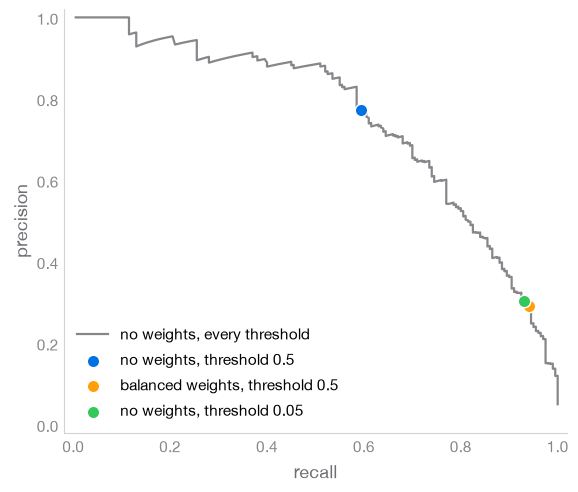

In [24]:
assert p_weighted is not None, "Fill in weighted_model and p_weighted above"
assert confusion_counts(y_test, flagged) is not None, "Finish Exercise 1.1 first"
assert precision_recall_f1(1, 1, 1) is not None, "Finish Exercise 1.2 first"
assert pr_points(hand_fake, hand_score) is not None, "Finish Exercise 3.4 first"
assert np.shape(p_weighted) == (4000,), "Expect one probability per test listing: the column [:, 1]"
assert confusion_counts(y_test, p_weighted >= 0.5)[:2] == (
    188,
    457,
), "Expect TP 188 and FP 457: fit on the training listings with class_weight='balanced'"

variants = [
    ("no weights, threshold 0.5", p_test, 0.5),
    ("balanced weights, threshold 0.5", p_weighted, 0.5),
    ("no weights, threshold 0.05", p_test, 0.05),
]
points = []
print(
    "model                              TP    FP   precision   recall   ROC-AUC   mean probability"
)
for name, proba, t in variants:
    tp, fp, fn, tn = confusion_counts(y_test, proba >= t)
    precision, recall, f1 = precision_recall_f1(tp, fp, fn)
    points.append((recall, precision))
    print(
        f"{name:32s} {tp:4d} {fp:5d} {precision:11.3f} {recall:8.3f} "
        f"{roc_auc_score(y_test, proba):9.3f} {proba.mean():18.3f}"
    )
print(f"the share of fakes in the test set: {y_test.mean():.3f}")

pr_precision, pr_recall = pr_points(y_test, p_test)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(pr_recall, pr_precision, color=INK3, lw=1.6, label="no weights, every threshold")
for (name, _, _), (recall, precision), color in zip(
    variants, points, [ACCENT, ORANGE, GREEN], strict=True
):
    ax.scatter([recall], [precision], s=80, color=color, edgecolor="white", zorder=4, label=name)
ax.set(xlabel="recall", ylabel="precision", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
ax.legend(loc="lower left")
plt.show()

At the threshold 0.5 the weighted model catches 188 of the 200 fakes, a recall of 0.940. It pays with 457 false alarms, and precision falls to 0.291. Its ROC-AUC is 0.971, as before, so the order of the listings hardly changed. The level of the probabilities did: the mean prediction is 0.195 while the true share of fakes is 0.05. The unweighted model gives 0.054. Weighted probabilities are no longer calibrated, so the cost rule of section 2.1 does not apply to them.

The last row is the unweighted model with the threshold 1 / (1 + 19) = 0.05. It has a recall of 0.930 and a precision of 0.302, almost the same point, and on the plot the weighted model lies next to the unweighted curve. Reweighting the classes and moving the threshold do nearly the same thing. The page `03_class_weights.html` moves the weight from 1 to 19.

### 4.2 Cross-validation with a metric of our choice

Choices about the model belong on the training data, by cross-validation as in week 3. A rare class changes two things. The first is the folds. A plain random split puts a different number of fakes into every fold, and a stratified split keeps the share of fakes the same in all of them.

In [25]:
plain_folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fakes_plain = [int(y_train[val_idx].sum()) for _, val_idx in plain_folds.split(X_train)]
fakes_stratified = [int(y_train[val_idx].sum()) for _, val_idx in folds.split(X_train, y_train)]
print("fakes in each validation fold, KFold:          ", fakes_plain)
print("fakes in each validation fold, StratifiedKFold:", fakes_stratified)

fakes in each validation fold, KFold:           [19, 17, 26, 20, 18]
fakes in each validation fold, StratifiedKFold: [20, 20, 20, 20, 20]


With `KFold` the folds hold between 17 and 26 fakes. `StratifiedKFold` puts exactly 20 into each.

The second is the score. For a classifier `cross_val_score` reports accuracy unless told otherwise. Its argument `scoring` takes the name of a metric: `"average_precision"`, `"roc_auc"`, `"f1"`, `"recall"` and others.

**Exercise 4.2.** Compute `cv_ap` and `cv_f1`: the scores of `make_model()` on the five stratified folds, first with `scoring="average_precision"`, then with `scoring="f1"`.

In [26]:
cv_ap = cross_val_score(make_model(), X_train, y_train, cv=folds, scoring="average_precision")
cv_f1 = cross_val_score(make_model(), X_train, y_train, cv=folds, scoring="f1")

In [27]:
assert cv_ap is not None and cv_f1 is not None, "Fill in cv_ap and cv_f1 above"
assert np.isclose(
    np.mean(cv_ap), 0.728, atol=2e-3
), "Expect a mean average precision of 0.728: cv=folds, scoring='average_precision'"
assert np.isclose(np.mean(cv_f1), 0.594, atol=2e-3), "Expect a mean F1 of 0.594: scoring='f1'"
weighted_ap = cross_val_score(
    make_model("balanced"), X_train, y_train, cv=folds, scoring="average_precision"
)
weighted_f1 = cross_val_score(make_model("balanced"), X_train, y_train, cv=folds, scoring="f1")
print("average precision on the folds:", cv_ap.round(3))
print("F1 on the folds:               ", cv_f1.round(3))
print("                    average precision          F1")
print(
    f"no weights          {cv_ap.mean():9.3f} +- {cv_ap.std():.3f} {cv_f1.mean():9.3f} +- {cv_f1.std():.3f}"
)
print(
    f"balanced weights    {weighted_ap.mean():9.3f} +- {weighted_ap.std():.3f} "
    f"{weighted_f1.mean():9.3f} +- {weighted_f1.std():.3f}"
)

average precision on the folds: [0.76  0.565 0.702 0.814 0.8  ]
F1 on the folds:                [0.621 0.412 0.606 0.688 0.645]
                    average precision          F1
no weights              0.728 +- 0.090     0.594 +- 0.095
balanced weights        0.717 +- 0.089     0.422 +- 0.043


The mean average precision over the folds is 0.728, with a standard deviation of 0.090. A fold has only 20 fakes, so the folds disagree a lot. $F_1$ at the threshold 0.5 is 0.594. The weighted model has almost the same average precision, 0.717, and a lower $F_1$, 0.422: the weights move the point where the threshold 0.5 falls and hardly change the ranking.

### 4.3 The threshold is chosen on validation data

In section 2 we took the threshold 0.39 because it gave the best $F_1$ on the test listings, and then reported that $F_1$ on the same listings. The test set took part in a choice, which is the leak of week 1. The threshold is a hyperparameter, and the training data has to choose it.

`cross_val_predict` returns for every training listing the prediction of a model that never saw it: the model fitted on the other four folds. These are called out-of-fold predictions.

In [28]:
oof_labels = cross_val_predict(make_model(), X_train, y_train, cv=folds)  # 0 or 1 for every listing
print("out-of-fold predictions for the 2000 training listings, as a confusion matrix:")
print(confusion_matrix(y_train, oof_labels))

out-of-fold predictions for the 2000 training listings, as a confusion matrix:
[[1888   12]
 [  53   47]]


By default the predictions are labels, made with the threshold 0.5. To choose a threshold we need the probabilities.

**Exercise 4.3.** Compute `p_oof`, the out-of-fold probabilities of a fake for the 2 000 training listings: the same call with `method="predict_proba"`.

In [29]:
p_oof = cross_val_predict(make_model(), X_train, y_train, cv=folds, method="predict_proba")[:, 1]

best F1 on the out-of-fold predictions: 0.656 at the threshold 0.32
threshold                          F1 on the test set
0.50, the default                        0.672
0.32, chosen by validation              0.682
0.39, chosen on the test set            0.694


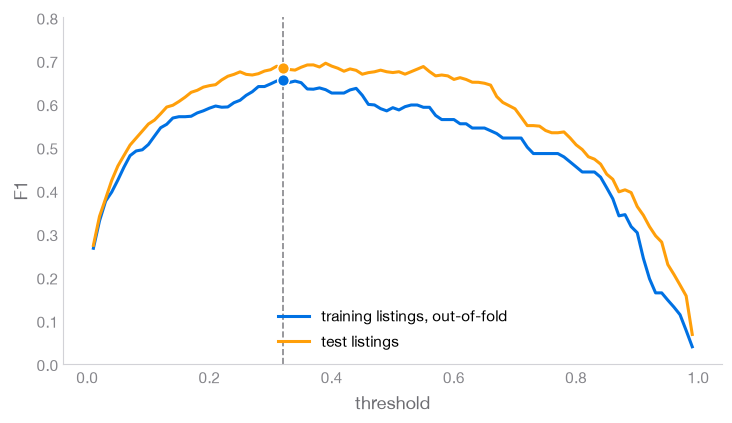

In [30]:
assert p_oof is not None, "Fill in p_oof above"
assert confusion_counts(y_test, flagged) is not None, "Finish Exercise 1.1 first"
assert precision_recall_f1(1, 1, 1) is not None, "Finish Exercise 1.2 first"
assert np.shape(p_oof) == (2000,), "Expect one probability per training listing: the column [:, 1]"


def f1_at(y, p, t):
    """F1 when the listings with a probability of at least t are flagged."""
    tp, fp, fn, tn = confusion_counts(y, p >= t)
    return precision_recall_f1(tp, fp, fn)[2]


f1_oof = np.array([f1_at(y_train, p_oof, t) for t in thresholds])
f1_test = np.array([f1_at(y_test, p_test, t) for t in thresholds])
t_val = thresholds[f1_oof.argmax()]  # chosen without the test set
t_peek = thresholds[f1_test.argmax()]  # chosen on the test set, as in section 2
assert np.isclose(t_val, 0.32), "Expect the threshold 0.32: cv=folds, method='predict_proba'"
print(f"best F1 on the out-of-fold predictions: {f1_oof.max():.3f} at the threshold {t_val:.2f}")
print("threshold                          F1 on the test set")
print(f"0.50, the default           {f1_at(y_test, p_test, 0.5):18.3f}")
print(f"{t_val:.2f}, chosen by validation {f1_at(y_test, p_test, t_val):18.3f}")
print(f"{t_peek:.2f}, chosen on the test set {f1_at(y_test, p_test, t_peek):16.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(thresholds, f1_oof, color=ACCENT, label="training listings, out-of-fold")
ax.plot(thresholds, f1_test, color=ORANGE, label="test listings")
ax.scatter([t_val], [f1_oof.max()], s=70, color=ACCENT, edgecolor="white", zorder=4)
ax.scatter([t_val], [f1_at(y_test, p_test, t_val)], s=70, color=ORANGE, edgecolor="white", zorder=4)
ax.axvline(t_val, color=INK3, ls="--", lw=1.2)
ax.set(xlabel="threshold", ylabel="F1", ylim=(0, 0.8))
ax.legend(loc="lower center")
plt.show()

On the out-of-fold predictions the best $F_1$ is 0.656, at the threshold 0.32. With this threshold the test $F_1$ is 0.682. That is better than the 0.672 of the default threshold and a little below the 0.694 we got by peeking. scikit-learn 1.5 and later has `TunedThresholdClassifierCV`, which does this search inside `fit`.

### 4.4 More than two classes

With $K$ classes the confusion matrix is $K \times K$: the rows are the true classes and the columns are the predicted ones. Precision and recall are computed for each class in turn, as if it were the positive one, and then averaged. The macro average is the plain mean over the classes. The weighted average weighs every class by its number of objects.

The data is `load_digits`, 8 by 8 images of handwritten digits. Its ten classes have almost equal sizes, so we keep only 20 images of each of the digits 8 and 9 to make two classes rare. The model is softmax regression from week 4.

In [31]:
digits = load_digits()  # bundled with scikit-learn, no download
rng = np.random.default_rng(SEED)
keep = np.ones(len(digits.target), dtype=bool)
for rare_digit in (8, 9):
    rows = np.flatnonzero(digits.target == rare_digit)
    keep[rng.choice(rows, size=len(rows) - 20, replace=False)] = False  # drop all but 20 images
digit_X_train, digit_X_test, digit_train, digit_test = train_test_split(
    digits.data[keep],
    digits.target[keep],
    test_size=0.5,
    random_state=SEED,
    stratify=digits.target[keep],
)
softmax = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10_000, tol=1e-10))
softmax.fit(digit_X_train, digit_train)
digit_pred = softmax.predict(digit_X_test)
print("test images of each digit:", np.bincount(digit_test))
print(f"accuracy on the {len(digit_test)} test images: {np.mean(digit_pred == digit_test):.3f}")

test images of each digit: [89 91 88 92 91 91 91 89 10 10]
accuracy on the 742 test images: 0.976


**Exercise 4.4.** Compute the confusion matrix `cm` with `confusion_matrix`, then from it the recall of every class, their macro average and their weighted average.

In [32]:
cm = confusion_matrix(digit_test, digit_pred)  # rows: the true digit, columns: the predicted one
class_sizes = cm.sum(axis=1)  # the number of test images of each digit
recall_per_class = np.diag(cm) / class_sizes
macro_recall = recall_per_class.mean()
weighted_recall = np.sum(recall_per_class * class_sizes) / class_sizes.sum()

recall of each digit: [1.   0.98 0.97 0.98 0.99 0.98 0.98 1.   0.7  0.7 ]
macro average 0.927, weighted average 0.976, accuracy 0.976

              precision    recall  f1-score   support

           0      0.989     1.000     0.994        89
           1      0.957     0.978     0.967        91
           2      0.977     0.966     0.971        88
           3      0.989     0.978     0.984        92
           4      0.989     0.989     0.989        91
           5      1.000     0.978     0.989        91
           6      1.000     0.978     0.989        91
           7      0.937     1.000     0.967        89
           8      0.778     0.700     0.737        10
           9      0.875     0.700     0.778        10

    accuracy                          0.976       742
   macro avg      0.949     0.927     0.937       742
weighted avg      0.976     0.976     0.975       742



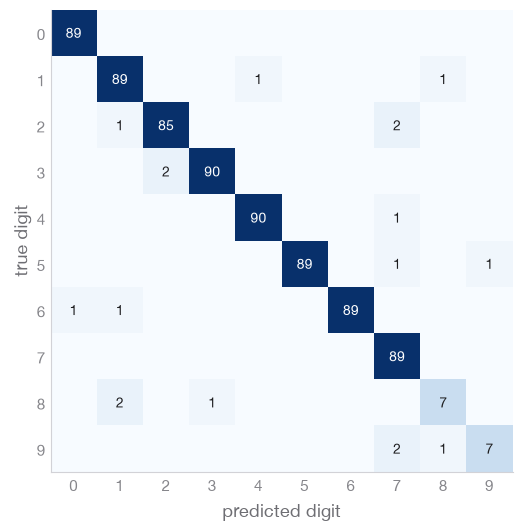

In [33]:
assert cm is not None, "Fill in cm above"
assert recall_per_class is not None, "Fill in recall_per_class above"
assert (
    macro_recall is not None and weighted_recall is not None
), "Fill in macro_recall and weighted_recall above"
assert np.isclose(
    macro_recall, recall_score(digit_test, digit_pred, average="macro")
), "The macro average is the plain mean of the ten recalls"
assert np.isclose(
    weighted_recall, recall_score(digit_test, digit_pred, average="weighted")
), "The weighted average is sum(recall * class size) / sum(class size)"
print("recall of each digit:", recall_per_class.round(2))
print(
    f"macro average {macro_recall:.3f}, weighted average {weighted_recall:.3f}, "
    f"accuracy {np.mean(digit_pred == digit_test):.3f}\n"
)
print(classification_report(digit_test, digit_pred, digits=3))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(cm, cmap="Blues", vmax=30)
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0:
            ax.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center",
                fontsize=10,
                color="white" if cm[i, j] > 15 else INK,
            )
ax.set(xticks=range(10), yticks=range(10), xlabel="predicted digit", ylabel="true digit")
plt.show()

Accuracy is 0.976, and the weighted average of the recalls is the same number: weighting by class size always gives accuracy back. The macro average is 0.927. The two rare digits count in it as much as any other, and the model finds only 7 of the 10 eights and 7 of the 10 nines. `classification_report` prints precision, recall and $F_1$ for every class with both averages. When the rare classes matter, read the macro average and the rows of those classes.

## Part B. Optimisation

Logistic regression has no closed form, so every model above was fitted by an iterative method inside scikit-learn. This part writes such methods by hand. Three things decide how fast they are: the length of the step, its direction, and how much data a step uses.

## 5. Gradient descent and the condition number

The data is the 40 flats of week 4: `markup` in percent, `metro`, the distance to the nearest metro station in km, and `sold`, 1 if the flat sold within 30 days. The model is logistic regression with an intercept. Its loss is the mean log-loss $L(\mathbf{w})$ with the gradient from week 4,

$$\nabla L(\mathbf{w}) = \frac{1}{n} A^\top (\mathbf{p} - \mathbf{y}), \qquad \mathbf{p} = \sigma(A \mathbf{w}),$$

where $A$ is the feature matrix with a column of ones in front. We keep the features in three versions: raw, centred (the means subtracted) and standardised (the means subtracted, then divided by the standard deviations).

In [34]:
def sold_sample(seed, n):
    """n flats of week 4: markup in % and metro in km as a matrix, and sold (0 or 1)."""
    rng = np.random.default_rng(seed)
    markup = np.round(rng.uniform(-15, 25, n), 0)
    metro = np.round(rng.uniform(0.2, 4.0, n), 1)
    logit = 2.0 - 0.20 * markup - 0.8 * metro  # the true log-odds of selling within 30 days
    sold = (rng.uniform(size=n) < sigmoid(logit)).astype(int)
    return np.column_stack([markup, metro]), sold


def design(X):
    """Put a column of ones in front: the first weight is the intercept."""
    return np.column_stack([np.ones(len(X)), X])


def mean_log_loss(A, y, w):
    """The mean log-loss of the weights w on the matrix A (ones in the first column)."""
    p = np.clip(sigmoid(A @ w), 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def gradient_of(A, y):
    """The gradient of the mean log-loss as a function of the weights."""

    def grad(w):
        return A.T @ (sigmoid(A @ w) - y) / len(y)

    return grad


def hessian_at(A, w):
    """The Hessian of the mean log-loss at the weights w: A^T S A / n with S = diag(p (1 - p))."""
    p = sigmoid(A @ w)
    return A.T @ (A * (p * (1 - p))[:, None]) / len(A)


def newton_minimum(A, y):
    """The weights at the minimum of the log-loss, by Newton's method (week 4)."""
    w = np.zeros(A.shape[1])
    for _ in range(50):
        p = sigmoid(A @ w)
        gradient = A.T @ (p - y)
        if np.linalg.norm(gradient) < 1e-10:
            break
        hessian = A.T @ (A * (p * (1 - p))[:, None])
        w = w - np.linalg.solve(hessian, gradient)
    return w


def losses_along(path, A, y):
    """The loss at every point of a path of weights."""
    return np.array([mean_log_loss(A, y, w) for w in path])


def steps_to_reach(losses, target):
    """The number of the first step with a loss of at most the target (None if there is none)."""
    hits = np.flatnonzero(losses <= target)
    return int(hits[0]) if len(hits) else None


def moves(optimiser):
    """True if the optimiser changes the weights. The checks use it to see that it is written."""
    path = optimiser(lambda w: w, np.ones(2), 0.1, 3)
    return not np.allclose(path[-1], path[0])


flats_X, flats_y = sold_sample(24, 40)
flat_versions = {
    "raw": flats_X,
    "centred": flats_X - flats_X.mean(axis=0),
    "standardised": (flats_X - flats_X.mean(axis=0)) / flats_X.std(axis=0),
}
print(f"{len(flats_y)} flats, {flats_y.sum()} sold within 30 days")
print("the first three flats (markup in %, metro in km):")
print(flats_X[:3])

40 flats, 19 sold within 30 days
the first three flats (markup in %, metro in km):
[[-2.   0.9]
 [ 1.   1.2]
 [ 8.   1. ]]


Gradient descent starts from some weights and repeats one step:

$$\mathbf{w} \leftarrow \mathbf{w} - \eta \, \nabla L(\mathbf{w}).$$

The learning rate $\eta$ is the length of the step. On a parabola with the curvature $L$ gradient descent converges only when $\eta < 2 / L$. The curvatures of our loss are the eigenvalues of its Hessian $\frac{1}{n} A^\top S A$, where $S$ is diagonal with the entries $p_i (1 - p_i) \le \frac{1}{4}$. So the largest eigenvalue of $A^\top A / (4n)$ bounds the curvature from above at every point. We call this bound $L$ and use the step $\eta = 1 / L$.

**Exercise 5.1.** Finish `gradient_descent`: add the step inside the loop.

In [35]:
def gradient_descent(grad, w0, eta, steps):
    """Plain gradient descent. Returns the path: the start and the weights after every step."""
    w = np.array(w0, dtype=float)
    path = [w.copy()]
    for _ in range(steps):
        w = w - eta * grad(w)
        path.append(w.copy())
    return np.array(path)

In [36]:
A_std = design(flat_versions["standardised"])
w_min = newton_minimum(A_std, flats_y)
loss_min = mean_log_loss(A_std, flats_y, w_min)
L_std = np.linalg.eigvalsh(A_std.T @ A_std / (4 * len(flats_y)))[-1]  # the largest eigenvalue

path = gradient_descent(gradient_of(A_std, flats_y), np.zeros(3), 1 / L_std, 100)
assert not np.allclose(
    path[-1], path[0]
), "Fill in gradient_descent above: the weights do not move yet"
losses = losses_along(path, A_std, flats_y)
steps_std = steps_to_reach(losses, loss_min + 0.001)
assert steps_std == 11, "Expect 11 steps on the standardised features: w = w - eta * grad(w)"
print(f"the minimum of the loss (Newton's method): {loss_min:.4f}")
print(
    f"gradient descent with the step 1/L = {1 / L_std:.2f}: loss {losses[0]:.4f} at the start, "
    f"{losses[5]:.4f} after 5 steps, {losses[steps_std]:.4f} after {steps_std}"
)
print(f"within 0.001 of the minimum after {steps_std} steps")

the minimum of the loss (Newton's method): 0.3971
gradient descent with the step 1/L = 3.61: loss 0.6931 at the start, 0.4034 after 5 steps, 0.3978 after 11
within 0.001 of the minimum after 11 steps


On the standardised features gradient descent is within 0.001 of the minimum after 11 steps.

The largest curvature limits the step. The smallest one decides how long the walk takes, because along the flattest direction a step of that length makes little progress. Their ratio is the condition number of the problem:

$$\kappa = \frac{\lambda_{\max}}{\lambda_{\min}}.$$

**Exercise 5.2.** Finish `condition_number(A, w)`: the largest eigenvalue of the Hessian at `w` divided by the smallest.

In [37]:
def condition_number(A, w):
    """The largest eigenvalue of the Hessian of the mean log-loss at w over the smallest."""
    eigenvalues = np.linalg.eigvalsh(hessian_at(A, w))  # sorted, the smallest first
    return eigenvalues[-1] / eigenvalues[0]

features       condition number   step 1/L   steps to within 0.001   minimum
raw                         671      0.029                    3923    0.3971
centred                     136      0.034                     664    0.3971
standardised               4.52        3.6                      11    0.3971


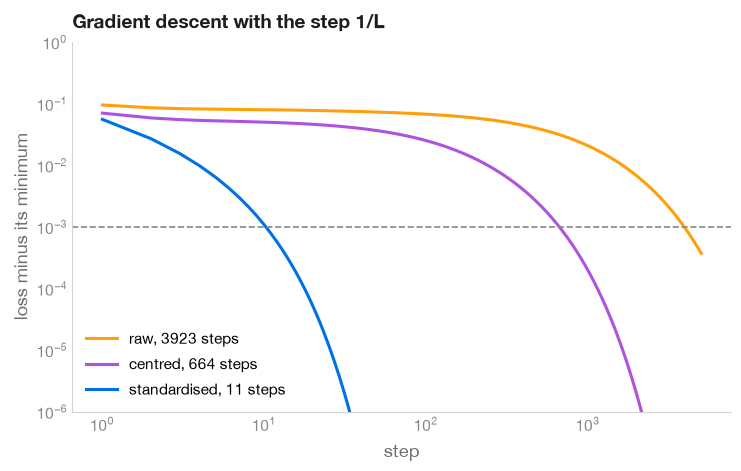

In [38]:
assert moves(gradient_descent), "Finish Exercise 5.1 first"
assert condition_number(A_std, w_min) is not None, "Fill in condition_number above"
assert np.isclose(
    condition_number(A_std, w_min), 4.5, atol=0.05
), "Expect 4.5 on the standardised features: the largest eigenvalue over the smallest"

flat_runs = {}
print("features       condition number   step 1/L   steps to within 0.001   minimum")
for name, features in flat_versions.items():
    A = design(features)
    w_min = newton_minimum(A, flats_y)
    loss_min = mean_log_loss(A, flats_y, w_min)
    kappa = condition_number(A, w_min)
    L = np.linalg.eigvalsh(A.T @ A / (4 * len(flats_y)))[-1]
    losses = losses_along(
        gradient_descent(gradient_of(A, flats_y), np.zeros(3), 1 / L, 5000), A, flats_y
    )
    steps = steps_to_reach(losses, loss_min + 0.001)
    flat_runs[name] = {"kappa": kappa, "eta": 1 / L, "steps": steps, "gap": losses - loss_min}
    print(f"{name:14s} {kappa:16.3g} {1 / L:10.2g} {steps:23d} {loss_min:9.4f}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (name, run), color in zip(flat_runs.items(), [ORANGE, PURPLE, ACCENT], strict=True):
    ax.plot(np.arange(1, 5001), run["gap"][1:], color=color, label=f"{name}, {run['steps']} steps")
ax.axhline(0.001, color=INK3, ls="--", lw=1.2)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="step",
    ylabel="loss minus its minimum",
    ylim=(1e-6, 1),
    title="Gradient descent with the step 1/L",
)
ax.legend(loc="lower left")
plt.show()

The three versions describe the same flats and have the same minimum, 0.3971. On the raw features the condition number is 671 and gradient descent needs 3 923 steps. Centring brings the condition number to 136 and the count to 664 steps. Standardising brings them to 4.5 and 11. This is why week 2 told us to scale the features before gradient descent. Ridge helps in the same way: it adds $\lambda$ to every eigenvalue, and the ratio of the largest to the smallest goes down. The page `04_step_size_and_ravine.html` runs the three versions.

## 6. Momentum and Adam

### 6.1 A toy bowl

The simplest loss with two different curvatures is

$$f(\mathbf{w}) = \tfrac{1}{2} \left( w_1^2 + 25 \, w_2^2 \right), \qquad \nabla f(\mathbf{w}) = (w_1, \; 25 \, w_2).$$

The curvatures are $\mu = 1$ and $L = 25$, so $\kappa = 25$. We start at $(10, 1)$, where the loss is 62.5, and count the steps until the loss is at most 0.001.

step 0.0200: 268 steps, loss after 20 steps 22.3
step 0.0769: 69 steps, loss after 20 steps 2.54
step 0.0850: diverges, loss after 20 steps 1.39e+03


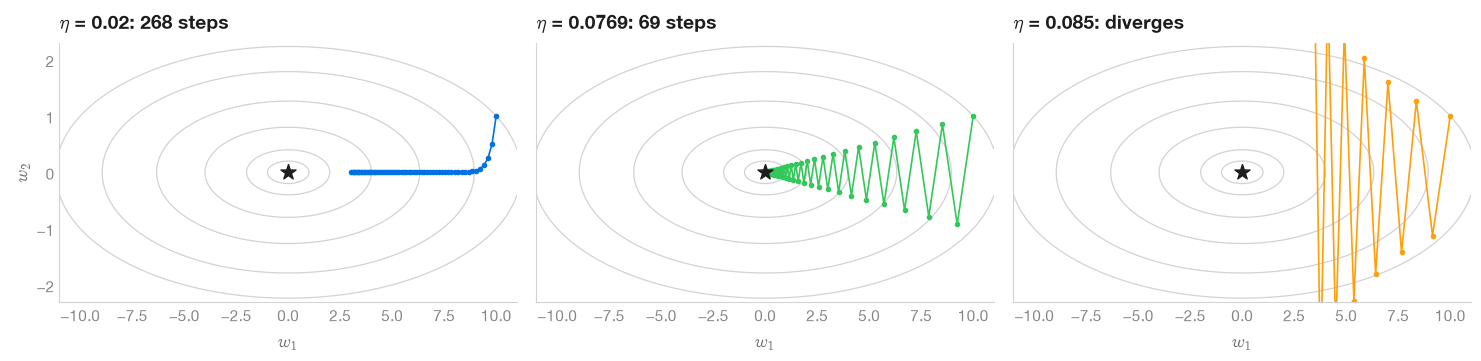

In [39]:
assert moves(gradient_descent), "Finish Exercise 5.1 first"
KAPPA = 25.0
BOWL_START = np.array([10.0, 1.0])


def bowl_loss(w):
    """The loss of the toy bowl. Works for one point and for an array of points."""
    w = np.asarray(w, dtype=float)
    return 0.5 * (w[..., 0] ** 2 + KAPPA * w[..., 1] ** 2)


def bowl_grad(w):
    return np.array([w[0], KAPPA * w[1]])


def draw_bowl(ax, path, color, title, n_shown=60):
    """Contour lines of the bowl and the first steps of a path."""
    w1, w2 = np.meshgrid(np.linspace(-11, 11, 200), np.linspace(-2.3, 2.3, 200))
    ax.contour(
        w1,
        w2,
        bowl_loss(np.stack([w1, w2], axis=-1)),
        levels=[0.5, 2, 8, 20, 40, 62.5],
        colors=LINE,
        linewidths=0.9,
    )
    ax.plot(path[:n_shown, 0], path[:n_shown, 1], "o-", ms=3, lw=1.2, color=color)
    ax.scatter([0], [0], marker="*", s=130, color=INK, zorder=5)
    ax.set(xlim=(-11, 11), ylim=(-2.3, 2.3), xlabel="$w_1$", title=title)


bowl_gd = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, eta, color in zip(axes, [0.02, 2 / 26, 0.085], [ACCENT, GREEN, ORANGE], strict=True):
    path = gradient_descent(bowl_grad, BOWL_START, eta, 400)
    bowl_gd[eta] = steps_to_reach(bowl_loss(path), 0.001)
    count = f"{bowl_gd[eta]} steps" if bowl_gd[eta] else "diverges"
    print(f"step {eta:.4f}: {count}, loss after 20 steps {bowl_loss(path[20]):.3g}")
    draw_bowl(ax, path, color, rf"$\eta$ = {eta:.3g}: {count}", n_shown=13 if eta > 0.08 else 60)
axes[0].set_ylabel("$w_2$")
fig.tight_layout()
plt.show()

The steep direction $w_2$ sets the limit: the step has to stay below $2 / L = 0.08$. At 0.085 every step jumps across the valley and lands further out than before. The step 0.02 is safe and slow along $w_1$, and it needs 268 steps. The best constant step is $2 / (L + \mu) = 2 / 26$. With it the distance to the minimum shrinks by the factor $(\kappa - 1) / (\kappa + 1) = 0.92$ at every step, the run takes 69 steps, and the path zigzags across the valley all the way. The number of steps grows in proportion to $\kappa$.

### 6.2 Momentum

Momentum, also called the heavy ball method, keeps a running sum of the gradients, the velocity $\mathbf{v}$, and steps along it:

$$\mathbf{v} \leftarrow \beta \, \mathbf{v} + \nabla L(\mathbf{w}), \qquad \mathbf{w} \leftarrow \mathbf{w} - \eta \, \mathbf{v}.$$

Across the valley consecutive gradients point in opposite directions and partly cancel in the sum. Along the valley they point the same way and add up, so the walk speeds up there.

**Exercise 6.1.** Finish `momentum`: start the velocity at zero and add the two updates inside the loop.

In [40]:
def momentum(grad, w0, eta, steps, beta=0.9):
    """Gradient descent with momentum (heavy ball). Returns the path of the weights."""
    w = np.array(w0, dtype=float)
    path = [w.copy()]
    v = np.zeros_like(w)  # the velocity starts at zero
    for _ in range(steps):
        v = beta * v + grad(w)
        w = w - eta * v
        path.append(w.copy())
    return np.array(path)

gradient descent, step 2/26:              69 steps
momentum, step 0.111, beta 0.444:        21 steps
momentum, step 0.07, beta 0.64:           12 steps
momentum, step 0.02, beta 0.9:            82 steps
the highest loss on the path of momentum: 79.0, at the step 1


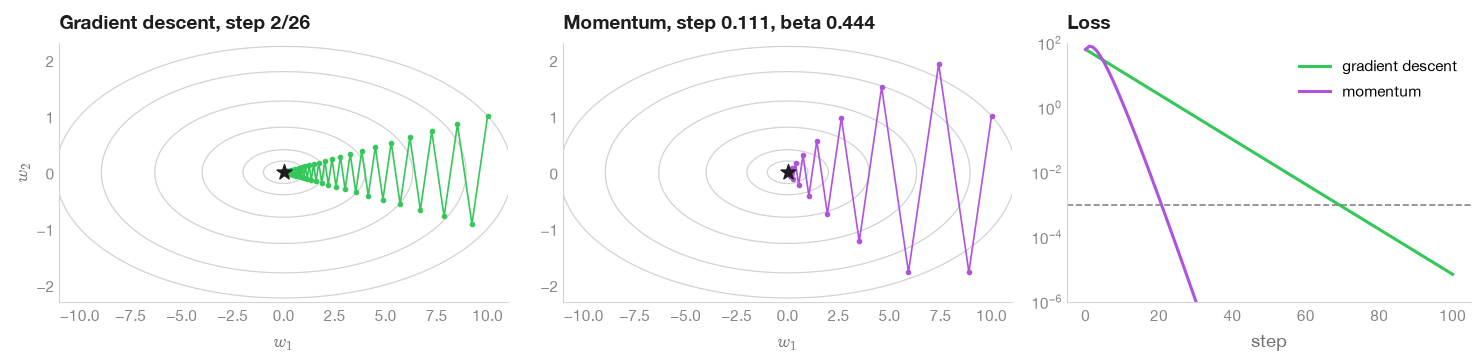

In [41]:
assert moves(gradient_descent), "Finish Exercise 5.1 first"
assert moves(momentum), "Fill in momentum above: the weights do not move yet"
eta_rate, beta_rate = 4 / 36, 4 / 9  # the pair with the best long-run rate, see below
path_gd = gradient_descent(bowl_grad, BOWL_START, 2 / 26, 100)
path_momentum = momentum(bowl_grad, BOWL_START, eta_rate, 100, beta=beta_rate)
steps_momentum = steps_to_reach(bowl_loss(path_momentum), 0.001)
assert steps_momentum == 21, "Expect 21 steps: v = beta * v + grad(w), then w = w - eta * v"
print(
    f"gradient descent, step 2/26:              {steps_to_reach(bowl_loss(path_gd), 0.001)} steps"
)
print(f"momentum, step {eta_rate:.3f}, beta {beta_rate:.3f}:        {steps_momentum} steps")
steps_other = steps_to_reach(
    bowl_loss(momentum(bowl_grad, BOWL_START, 0.07, 100, beta=0.64)), 0.001
)
print(f"momentum, step 0.07, beta 0.64:           {steps_other} steps")
steps_default = steps_to_reach(bowl_loss(momentum(bowl_grad, BOWL_START, 0.02, 400)), 0.001)
print(f"momentum, step 0.02, beta 0.9:            {steps_default} steps")
print(
    f"the highest loss on the path of momentum: {bowl_loss(path_momentum).max():.1f}, "
    f"at the step {bowl_loss(path_momentum).argmax()}"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), width_ratios=[1, 1, 0.9])
draw_bowl(axes[0], path_gd, GREEN, "Gradient descent, step 2/26")
draw_bowl(axes[1], path_momentum, PURPLE, "Momentum, step 0.111, beta 0.444")
axes[0].set_ylabel("$w_2$")
axes[2].plot(bowl_loss(path_gd), color=GREEN, label="gradient descent")
axes[2].plot(bowl_loss(path_momentum), color=PURPLE, label="momentum")
axes[2].axhline(0.001, color=INK3, ls="--", lw=1.2)
axes[2].set(yscale="log", ylim=(1e-6, 100), xlabel="step", title="Loss")
axes[2].legend()
fig.tight_layout()
plt.show()

For a bowl with the curvatures $\mu$ and $L$ the pair $\eta = 4 / (\sqrt{L} + \sqrt{\mu})^2 = 0.111$ and $\beta = \big( (\sqrt{\kappa} - 1) / (\sqrt{\kappa} + 1) \big)^2 = 0.444$ gives the best rate in the long run. With it momentum needs 21 steps where gradient descent needed 69: the factor per step improves from $(\kappa - 1) / (\kappa + 1)$ to $(\sqrt{\kappa} - 1) / (\sqrt{\kappa} + 1)$, here from 0.92 to 0.67. The first step swings wide across the valley, and the loss goes up to 79.0 before it falls. The pair is the best one only in the long run: from our start, $\eta = 0.07$ with $\beta = 0.64$ reaches a loss of 0.001 in 12 steps. With the small step 0.02 and $\beta = 0.9$ momentum takes 82 steps, against 268 for gradient descent with the same step.

### 6.3 Adam

Adam gives every coordinate its own step. It keeps a running mean $\mathbf{m}$ of the gradient $\mathbf{g} = \nabla L(\mathbf{w})$ and a running mean $\mathbf{s}$ of its square, and divides the first by the root of the second:

$$\mathbf{m} \leftarrow \beta_1 \mathbf{m} + (1 - \beta_1) \, \mathbf{g}, \qquad \mathbf{s} \leftarrow \beta_2 \mathbf{s} + (1 - \beta_2) \, \mathbf{g}^2,$$

$$\hat{\mathbf{m}} = \frac{\mathbf{m}}{1 - \beta_1^t}, \qquad \hat{\mathbf{s}} = \frac{\mathbf{s}}{1 - \beta_2^t}, \qquad \mathbf{w} \leftarrow \mathbf{w} - \eta \, \frac{\hat{\mathbf{m}}}{\sqrt{\hat{\mathbf{s}}} + \varepsilon}.$$

The square, the root and the division work coordinate by coordinate, and $t = 1, 2, \dots$ is the number of the step. Both means start at zero, and the division by $1 - \beta^t$ corrects for that start. A coordinate with large gradients gets a short step and a coordinate with small gradients a long one, so the scale of a feature matters much less. The usual values are $\beta_1 = 0.9$, $\beta_2 = 0.999$ and $\varepsilon = 10^{-8}$. RMSProp is the same idea without $\mathbf{m}$: it divides the gradient itself by $\sqrt{\mathbf{s}}$.

**Exercise 6.2.** Finish `adam`: start both means at zero and add the updates inside the loop.

In [42]:
def adam(grad, w0, eta, steps, beta1=0.9, beta2=0.999, eps=1e-8):
    """Adam. Returns the path of the weights."""
    w = np.array(w0, dtype=float)
    path = [w.copy()]
    m, s = np.zeros_like(w), np.zeros_like(w)  # both running means start at zero
    t = 0
    for _ in range(steps):
        t += 1  # the number of this step, for the bias correction
        g = grad(w)
        m = beta1 * m + (1 - beta1) * g
        s = beta2 * s + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**t)
        s_hat = s / (1 - beta2**t)
        w = w - eta * m_hat / (np.sqrt(s_hat) + eps)
        path.append(w.copy())
    return np.array(path)

the toy bowl, Adam with the step 0.5: 80 steps

the 40 flats, centred features     steps to within 0.001
gradient descent, step 1/L                           664
momentum, beta 0.9, step 1/L                          58
Adam, step 0.1                                        39


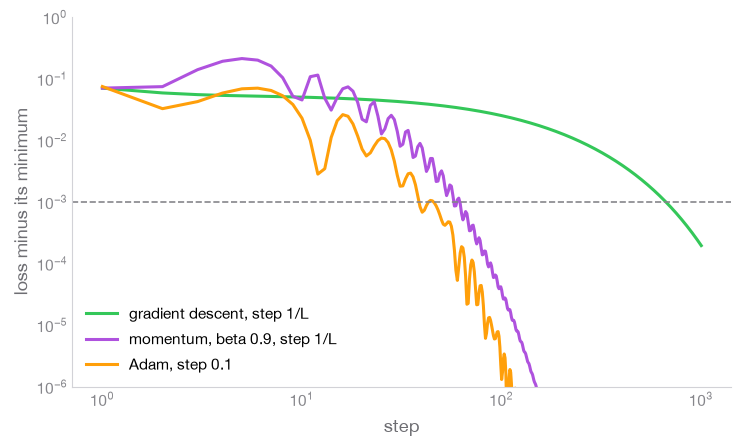

In [43]:
assert moves(gradient_descent), "Finish Exercise 5.1 first"
assert moves(momentum), "Finish Exercise 6.1 first"
assert moves(adam), "Fill in adam above: the weights do not move yet"
steps_adam_bowl = steps_to_reach(bowl_loss(adam(bowl_grad, BOWL_START, 0.5, 400)), 0.001)
assert steps_adam_bowl == 80, "Expect 80 steps on the bowl: check the bias correction with beta**t"
print(f"the toy bowl, Adam with the step 0.5: {steps_adam_bowl} steps\n")

A_centred = design(flat_versions["centred"])
grad_centred = gradient_of(A_centred, flats_y)
loss_min = mean_log_loss(A_centred, flats_y, newton_minimum(A_centred, flats_y))
eta_centred = 1 / np.linalg.eigvalsh(A_centred.T @ A_centred / (4 * len(flats_y)))[-1]
centred_paths = {
    "gradient descent, step 1/L": gradient_descent(grad_centred, np.zeros(3), eta_centred, 1000),
    "momentum, beta 0.9, step 1/L": momentum(grad_centred, np.zeros(3), eta_centred, 1000),
    "Adam, step 0.1": adam(grad_centred, np.zeros(3), 0.1, 1000),
}
centred_steps = {}
print("the 40 flats, centred features     steps to within 0.001")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (name, path), color in zip(centred_paths.items(), [GREEN, PURPLE, ORANGE], strict=True):
    losses = losses_along(path, A_centred, flats_y)
    centred_steps[name] = steps_to_reach(losses, loss_min + 0.001)
    print(f"{name:32s} {centred_steps[name]:23d}")
    ax.plot(np.arange(1, 1001), losses[1:] - loss_min, color=color, label=name)
ax.axhline(0.001, color=INK3, ls="--", lw=1.2)
ax.set(xscale="log", yscale="log", xlabel="step", ylabel="loss minus its minimum", ylim=(1e-6, 1))
ax.legend(loc="lower left")
plt.show()

On the bowl Adam with $\eta = 0.5$ takes 80 steps, more than gradient descent with the best step (69). That best step needs the curvatures, which we rarely know. On the centred flats gradient descent with the step $1 / L$ takes 664 steps, momentum with $\beta = 0.9$ and the same step takes 58, and Adam with $\eta = 0.1$ takes 39. The curves of momentum and Adam are not monotone: both overshoot and come back. The page `05_momentum_and_minibatches.html` shows the paths of all the methods on the bowl.

## 7. Mini-batch SGD

The gradient of the mean loss is a mean over all $n$ objects, so one step costs a pass over the whole dataset. Stochastic gradient descent (SGD) takes the mean over a random batch of $B$ objects. This is a noisy estimate of the full gradient that is right on average, and a step reads only $B$ rows. One pass over the data is called an epoch and has $n / B$ steps.

The data is 2 000 flats from the generator of week 4, standardised. Every run starts from zero weights, where the loss is $\log 2 = 0.693$.

In [44]:
big_X, big_y = sold_sample(77, 2000)
big_A = design(StandardScaler().fit_transform(big_X))
big_loss_min = mean_log_loss(big_A, big_y, newton_minimum(big_A, big_y))
print(f"{len(big_y)} flats, the minimum of the loss is {big_loss_min:.4f}")


def batches(order, batch):
    """Cut the row numbers in `order` into consecutive batches."""
    return [order[start : start + batch] for start in range(0, len(order), batch)]


def constant_step(t):
    """The step 0.5 at every step number t."""
    return 0.5

2000 flats, the minimum of the loss is 0.3709


**Exercise 7.1.** Write `sgd_step`: one step of SGD on the rows `idx` of a batch. The loop around it is in the next cell.

In [45]:
def sgd_step(A, y, w, idx, step):
    """One step of the length `step` on the rows idx of a batch. Returns the new weights."""
    gradient = A[idx].T @ (sigmoid(A[idx] @ w) - y[idx]) / len(idx)
    return w - step * gradient

In [46]:
def sgd(A, y, step_size, batch, epochs, seed=0):
    """Mini-batch SGD on the mean log-loss, from zero weights.

    Returns the loss on all the data after every epoch (the first value is the start) and
    the final weights. step_size(t) is the length of the step number t.
    """
    rng = np.random.default_rng(seed)
    w = np.zeros(A.shape[1])
    losses, t = [mean_log_loss(A, y, w)], 0
    for _ in range(epochs):
        for idx in batches(rng.permutation(len(y)), batch):  # a new random order every epoch
            t += 1
            w = sgd_step(A, y, w, idx, step_size(t))
            assert w is not None, "Fill in sgd_step above"
        losses.append(mean_log_loss(A, y, w))
    return np.array(losses), w


losses_full, _ = sgd(big_A, big_y, constant_step, 2000, 20)
assert np.isclose(
    losses_full[1], 0.635, atol=5e-4
), "Expect 0.635 after one full-batch step: A[idx].T @ (sigmoid(A[idx] @ w) - y[idx]) / len(idx)"
sgd_runs = {
    "batch size 2000 (full batch)": losses_full,
    "batch size 32": sgd(big_A, big_y, constant_step, 32, 20)[0],
    "batch size 1": sgd(big_A, big_y, constant_step, 1, 20)[0],
}
steps_per_epoch = {"batch size 2000 (full batch)": 1, "batch size 32": 63, "batch size 1": 2000}
print("the loss on all 2000 flats after 1, 2, 5 and 20 epochs")
print("                               steps per epoch       1       2       5      20")
for name, losses in sgd_runs.items():
    print(
        f"{name:30s} {steps_per_epoch[name]:15d} {losses[1]:7.3f} {losses[2]:7.3f} "
        f"{losses[5]:7.3f} {losses[20]:7.3f}"
    )
print(
    f"batch size 1 between epochs 1 and 20: from {sgd_runs['batch size 1'][1:].min():.3f} "
    f"to {sgd_runs['batch size 1'][1:].max():.3f}"
)

the loss on all 2000 flats after 1, 2, 5 and 20 epochs
                               steps per epoch       1       2       5      20
batch size 2000 (full batch)                 1   0.635   0.590   0.506   0.400
batch size 32                               63   0.373   0.372   0.373   0.372
batch size 1                              2000   0.387   0.443   0.416   0.463
batch size 1 between epochs 1 and 20: from 0.372 to 0.534


After one epoch the full batch has made a single step and its loss is 0.635. Batch size 32 has made 63 steps and stands at 0.373, almost at the minimum of 0.3709. Batch size 1 makes 2 000 steps per epoch and gets close fast, but it does not settle: 0.387 after one epoch, 0.443 after two, 0.463 after twenty. With a constant step the noise of the gradient never dies out, and the weights keep jumping around the minimum.

The remedy is a step that gets shorter as the run goes on.

**Exercise 7.2.** Write `decaying_step(t)`: the step $0.5 / (1 + t / 200)$ at the step number $t$.

In [47]:
def decaying_step(t):
    """A step that starts at 0.5 and halves by the step number 200."""
    return 0.5 / (1 + t / 200)

batch size 1, decaying step: the loss after 1, 2, 5 and 20 epochs: [0.377 0.373 0.371 0.371]


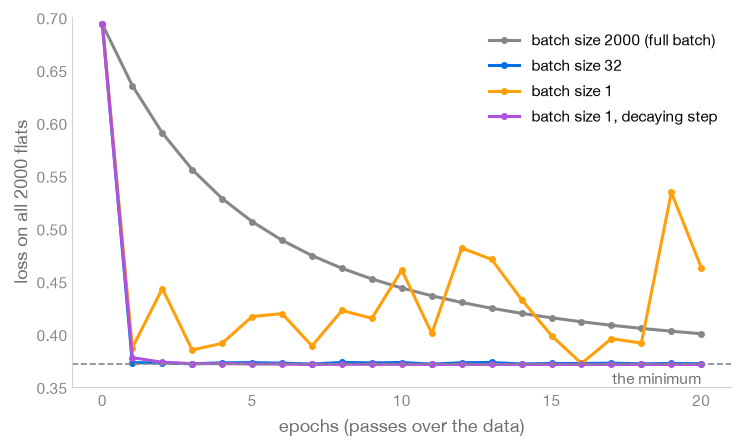

In [48]:
assert (
    sgd_step(big_A, big_y, np.zeros(3), np.arange(5), 0.5) is not None
), "Finish Exercise 7.1 first"
assert decaying_step(1) is not None, "Fill in decaying_step above"
assert np.isclose(decaying_step(200), 0.25), "Expect 0.25 at t = 200: 0.5 / (1 + 200 / 200)"
losses_decay = sgd(big_A, big_y, decaying_step, 1, 20)[0]
sgd_runs["batch size 1, decaying step"] = losses_decay
print(
    "batch size 1, decaying step: the loss after 1, 2, 5 and 20 epochs:",
    losses_decay[[1, 2, 5, 20]].round(3),
)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (name, losses), color in zip(sgd_runs.items(), [INK3, ACCENT, ORANGE, PURPLE], strict=True):
    ax.plot(np.arange(21), losses, "o-", ms=4, color=color, label=name)
ax.axhline(big_loss_min, color=INK3, ls="--", lw=1.2)
ax.annotate(
    "the minimum",
    (20, big_loss_min),
    xytext=(0, -14),
    textcoords="offset points",
    ha="right",
    fontsize=11,
    color=INK2,
)
ax.set(
    xlabel="epochs (passes over the data)",
    ylabel="loss on all 2000 flats",
    ylim=(0.35, 0.7),
    xticks=range(0, 21, 5),
)
ax.legend(loc="upper right")
plt.show()

With the decaying step batch size 1 is at 0.377 after one epoch and at 0.371 after five. Long steps at the start cover the distance, and short steps at the end average the noise out.

### 7.1 The same in scikit-learn

`SGDClassifier(loss="log_loss")` is logistic regression trained by SGD with batch size 1. It shuffles the data before every epoch and stops when the loss stops improving. `learning_rate="invscaling"` with `eta0=0.5` and `power_t=0.5` is the decaying step $0.5 / \sqrt{t}$.

In [49]:
big_Z = big_A[:, 1:]  # the standardised features without the column of ones
sgd_model = SGDClassifier(
    loss="log_loss",
    penalty=None,
    learning_rate="invscaling",
    eta0=0.5,
    power_t=0.5,
    random_state=SEED,
).fit(big_Z, big_y)
sgd_default = SGDClassifier(loss="log_loss", random_state=SEED).fit(big_Z, big_y)
lbfgs_model = LogisticRegression(C=np.inf).fit(big_Z, big_y)
print("                                      epochs   log-loss")
for name, fitted in [
    ("SGDClassifier, decaying step", sgd_model),
    ("SGDClassifier, default settings", sgd_default),
    ("LogisticRegression (L-BFGS)", lbfgs_model),
]:
    loss = log_loss(big_y, fitted.predict_proba(big_Z)[:, 1])
    print(f"{name:36s} {int(np.max(fitted.n_iter_)):7d} {loss:10.4f}")
print("weights, SGDClassifier:     ", np.append(sgd_model.intercept_, sgd_model.coef_[0]).round(2))
print(
    "weights, LogisticRegression:", np.append(lbfgs_model.intercept_, lbfgs_model.coef_[0]).round(2)
)

                                      epochs   log-loss
SGDClassifier, decaying step               7     0.3710
SGDClassifier, default settings           36     0.3781
LogisticRegression (L-BFGS)                7     0.3709
weights, SGDClassifier:      [-0.63 -2.32 -0.9 ]
weights, LogisticRegression: [-0.64 -2.33 -0.9 ]


`SGDClassifier` with the decaying step stops after 7 epochs at a log-loss of 0.371, next to the 0.3709 of `LogisticRegression`. With its default settings it adds an L2 penalty and uses another schedule, and it stops at 0.378. `LogisticRegression` uses L-BFGS, a second-order method that reads all the data at every step. On 2 000 flats that is the better tool. SGD pays off when the data is too large for full passes, and `partial_fit` lets `SGDClassifier` learn from data that arrives in pieces.

## 8. What to remember

- With a rare class accuracy says little. The confusion matrix holds everything: precision is TP / (TP + FP), recall is TP / (TP + FN), and $F_1$ is their harmonic mean.
- The threshold trades precision for recall. Choose it from the costs of the two mistakes or by a metric, on validation data. The test set gives one final number.
- ROC-AUC is the share of (positive, negative) pairs that the scores order correctly. With a rare class also look at the precision-recall curve, and remember that precision depends on the share of the class.
- Class weights move the model along almost the same curve as the threshold does, and they break calibration. Use stratified folds and pass `scoring` to cross-validation.
- Gradient descent needs a step below $2 / L$, and its number of steps grows with the condition number, so scale the features. Momentum and Adam are faster on badly conditioned problems.
- Mini-batches make steps cheap and noisy. A constant step leaves the weights jumping around the minimum, and a decaying step lets them settle.

## Try at home

1. The site grows and the share of fakes falls to 1%: draw `fake_sample(5002, 40000, share=0.01)` and apply `model` with the threshold 0.5. Compare its precision with the row for 1% in section 3.4.
2. $F_\beta = (1 + \beta^2) \, P R / (\beta^2 P + R)$ weighs recall $\beta$ times more than precision. Find the threshold with the best $F_2$ on the out-of-fold predictions of section 4.3. Is it lower or higher than 0.32?
3. Run `momentum` and `adam` on the raw features of the 40 flats (`flat_versions["raw"]`) with the settings of section 6.3 and the step $1 / L$ of the raw features. Gradient descent needed 3 923 steps there.
4. In section 7, try batch size 32 with the decaying step, and batch size 1 with the constant steps 0.05 and 0.005. What does a shorter constant step change?